## Dependencies

In [1]:
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
from IPython.display import display
from pdf2image import convert_from_path

In [3]:
import sys
sys.path.append('../libs')

%load_ext autoreload
%autoreload 2

import ios
import setup

Total combinations of features: 383


## Setup

In [4]:
VERSION = 3
RANDOM_SEED = 12345

VAR_X = ['mean', 'median', 'mode']
DIR = f'../../results/v{VERSION}/gender/predictions/comparison/rs{RANDOM_SEED}/classification/_<VAR_X>'
METRIC = 'test_auc'

## Data

In [5]:
df_results_mean = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mean'))
df_results_median = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'median'))
df_results_mode = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mode'))
df_results = pd.concat([df_results_mean, df_results_median, df_results_mode], ignore_index=True)
df_results.shape

(1915, 25)

In [6]:
df_results.columns

Index(['strategy_id', 'features_id', 'y', 'features', 'nfeatures',
       'cat_features', 'best_params', 'best_score', 'best_iteration',
       'test_size', 'random_state', 'loss_function', 'eval_metric',
       'train_eval', 'test_accuracy', 'test_f1', 'test_precision',
       'test_recall', 'test_auc', 'all_accuracy', 'all_f1', 'all_precision',
       'all_recall', 'all_auc', 'f_name'],
      dtype='object')

In [7]:
cols = ['y','features_id','strategy_id','train_eval','test_accuracy','all_accuracy','test_f1','test_precision','test_recall','test_auc','all_auc','f_name']
df_results[cols].sort_values(METRIC, ascending=False)

,y,features_id,strategy_id,train_eval,test_accuracy,all_accuracy,test_f1,test_precision,test_recall,test_auc,all_auc,f_name
1516,gender_median,342,4,0.214730,0.735294,0.825301,0.732730,0.763492,0.729138,0.935143,0.950382,median_342_4
881,gender_mean,31,2,0.306032,0.794118,0.710843,0.792929,0.798834,0.795455,0.933328,0.864745,mean_31_2
1339,gender_median,258,4,0.186349,0.764706,0.813253,0.752892,0.774603,0.750117,0.932905,0.949362,median_258_4
1421,gender_median,131,4,0.398503,0.735294,0.837349,0.729121,0.752747,0.724476,0.932844,0.956070,median_131_4
1415,gender_median,236,4,0.424027,0.735294,0.825301,0.729121,0.752747,0.724476,0.930259,0.943169,median_236_4
...,...,...,...,...,...,...,...,...,...,...,...,...
557,gender_mean,24,2,0.857069,0.529412,0.542169,0.412698,0.366667,0.515152,0.609190,0.656761,mean_24_2
1468,gender_median,24,4,0.622071,0.529412,0.542169,0.400901,0.347222,0.500000,0.598379,0.674431,median_24_4
1183,gender_median,2,4,0.691438,0.529412,0.542169,0.400901,0.347222,0.500000,0.581590,0.658991,median_2_4
1006,gender_mean,2,2,0.739285,0.529412,0.542169,0.412698,0.366667,0.515152,0.573781,0.636945,mean_2_2


In [8]:
best_id = df_results[METRIC].idxmax()
best_id

1516

In [9]:
df_results.loc[[best_id], ['y', 'features', 'train_eval','test_f1','test_auc']]

,y,features,train_eval,test_f1,test_auc
1516,gender_median,"[ngender_r, gender_n, gender_nw, mean_ngender_...",0.21473,0.73273,0.935143


In [10]:
df_results.loc[best_id].features

['ngender_r',
 'gender_n',
 'gender_nw',
 'mean_ngender_rn',
 'mean_ngender_rw',
 'mean_ngender_nw']

In [11]:
df_results.loc[best_id]

strategy_id                                                       4
features_id                                                     342
y                                                     gender_median
features          [ngender_r, gender_n, gender_nw, mean_ngender_...
nfeatures                                                         6
cat_features                                  [gender_n, gender_nw]
best_params       {'depth': 4, 'learning_rate': 0.1, 'l2_leaf_re...
best_score        {'learn': {'MultiClass': 0.21472977486342318},...
best_iteration                                                   94
test_size                                                       0.2
random_state                                                  12345
loss_function                                            MultiClass
eval_metric                                              MultiClass
train_eval                                                  0.21473
test_accuracy                                   

In [12]:
df_results.loc[best_id].strategy_id, setup.STRATEGY[df_results.loc[best_id].strategy_id]

(4, {'cuts': [0.3, 0.7], 'gt_agg': 'median'})

In [13]:
metric = df_results.loc[best_id].y.replace('gender_','')
f_name = DIR.replace('<VAR_X>', metric)
f_name = f"{f_name}/{metric}_{df_results.loc[best_id].features_id}_{df_results.loc[best_id].strategy_id}"
f_name

'../../results/v3/gender/predictions/comparison/rs12345/classification/_median/median_342_4'

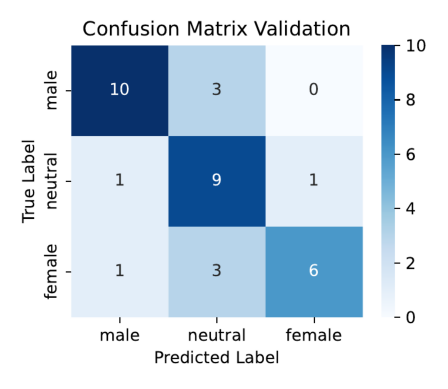

In [14]:
# predictions
fn = f"{f_name}_confusion_val.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



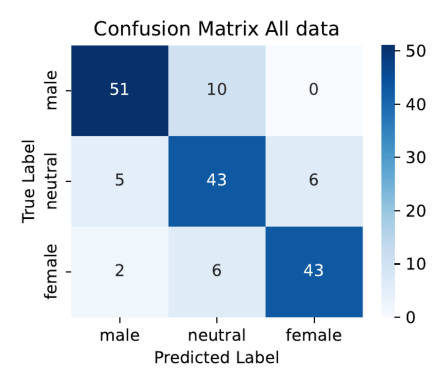

In [15]:
# predictions
fn = f"{f_name}_confusion_all.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



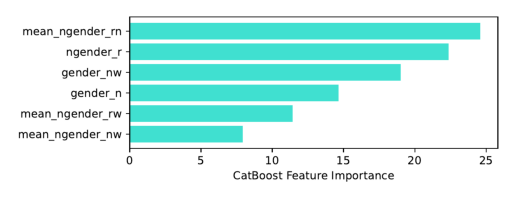

In [16]:
# predictors
fn = f"{f_name}_feature_importance.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()

